In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [2]:
df = pd.read_csv("Day40_Customer_Churn_Cleaned.csv")

df.shape

FileNotFoundError: [Errno 2] No such file or directory: 'Day40_Customer_Churn_Cleaned.csv'

In [3]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
C:\Users\amolb

Files in this folder:
['-1.14-windows.xml', '.bash_history', '.cache', '.docker', '.dotnet', '.eclipse', '.git', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.m2', '.nuget', '.p2', '.templateengine', '.vscode', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Day40_Customer_Churn_Project', 'docker', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'EF_Auto_Run', 'Favorites', 'java-2025-03', 'java-2025-032', 'jee-2025-03', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{76c39381-bf71-11ef-8438-e0bb4b1a9592}.TM.blf', 'NTUSER.DAT{76c39381-bf71-11ef-8438-e0bb4b1a9592}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{76c39381-bf71-11ef-8438-e0bb4b1a9592}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'PrintHood', 'Recent', 'Recruitment_of_Junior_Associates_(Customer_Support_&_Sales)_(Advertisement_No._CRP

In [4]:
os.listdir("Day40_Customer_Churn_Project")

['.ipynb_checkpoints',
 'Day40_Customer_Churn_Analysis.ipynb',
 'Day40_Customer_Churn_Cleaned.csv',
 'Day40_Customer_Churn_Practice_Raw.csv']

In [5]:
df = pd.read_csv(
    "Day40_Customer_Churn_Project/Day40_Customer_Churn_Cleaned.csv"
)

df.shape

(1000, 15)

In [6]:
df["Churn"].value_counts()

Churn
No     652
Yes    348
Name: count, dtype: int64

In [7]:
df.columns.tolist()

['CustomerID',
 'Gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'Tenure',
 'PhoneService',
 'InternetService',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'Tenure Group']

In [8]:
df.dtypes

CustomerID              str
Gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
Tenure                int64
PhoneService            str
InternetService         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
Tenure Group            str
dtype: object

In [9]:
df["Churn"].value_counts()

Churn
No     652
Yes    348
Name: count, dtype: int64

In [10]:
df["Churn"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [11]:
X= df.drop(columns="CustomerID","Churn","Tenure Group"])
X.head()

SyntaxError: closing parenthesis ']' does not match opening parenthesis '(' (1277958091.py, line 1)

In [12]:
X= df.drop(columns=["CustomerID","Churn","Tenure Group"])
X.head()

,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,male,0,No,No,7,Yes,fiber optic,one year,No,electronic check,1535.29,10916.49
1,male,0,No,No,56,Yes,no,two year,No,electronic check,1070.85,59986.77
2,female,0,Yes,No,48,Yes,no,month-to-month,Yes,bank transfer,529.52,25411.70
3,female,0,Yes,No,32,Yes,fiber optic,month-to-month,Yes,bank transfer,1405.80,44861.43
4,male,1,Yes,No,32,Yes,fiber optic,two year,Yes,credit card,380.95,12282.12


In [13]:
y =df["Churn"]
y.head()

0     No
1     No
2     No
3    Yes
4     No
Name: Churn, dtype: str

In [14]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

X shape: (1000, 12)
y shape: (1000,)

Input Features:
['Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'PhoneService', 'InternetService', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target Distribution:
Churn
No     652
Yes    348
Name: count, dtype: int64


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [16]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 12)
X_test: (200, 12)
y_train: (800,)
y_test: (200,)


In [17]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
Churn
No     522
Yes    278
Name: count, dtype: int64

Testing distribution:
Churn
No     130
Yes     70
Name: count, dtype: int64


In [18]:
categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Features:
['SeniorCitizen', 'Tenure', 'MonthlyCharges', 'TotalCharges']


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features),

        ("numerical",
         StandardScaler(),
         numerical_features)
    ]
)

print("Preprocessing setup completed successfully.")

Preprocessing setup completed successfully.


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print("Machine learning tools imported successfully.")

Machine learning tools imported successfully.


In [21]:
model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classification", LogisticRegression(max_iter=1000))
    ]
)

print("Churn prediction model created successfully.")

Churn prediction model created successfully.


In [22]:
model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [23]:
y_pred = model.predict(X_test)

print("Predictions completed successfully.")
print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions completed successfully.

First 10 predictions:
['No' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'No']


In [24]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 61.5 %


Confusion Matrix:
[[96 34]
 [43 27]]


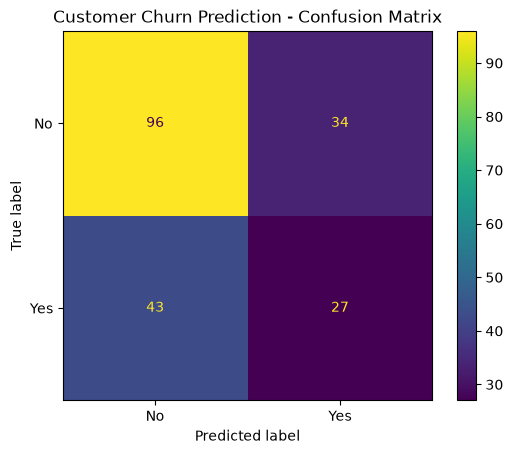

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

display.plot()
plt.title("Customer Churn Prediction - Confusion Matrix")
plt.show()

In [26]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred
)

print("Customer Churn Model - Classification Report")
print(report)

Customer Churn Model - Classification Report
              precision    recall  f1-score   support

          No       0.69      0.74      0.71       130
         Yes       0.44      0.39      0.41        70

    accuracy                           0.61       200
   macro avg       0.57      0.56      0.56       200
weighted avg       0.60      0.61      0.61       200



In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="Yes"
)

recall = recall_score(
    y_test, y_pred, pos_label="Yes"
)

f1 = f1_score(
    y_test, y_pred, pos_label="Yes"
)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

Accuracy: 61.5 %
Precision: 44.26 %
Recall: 38.57 %
F1 Score: 41.22 %


In [28]:
balanced_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classification", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

print("Balanced model training and prediction completed.")

Balanced model training and prediction completed.


In [29]:
from sklearn.metrics import classification_report

print("Balanced Model Classification Report:")
print(classification_report(y_test, balanced_pred))

Balanced Model Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.53      0.65       130
         Yes       0.48      0.81      0.61        70

    accuracy                           0.63       200
   macro avg       0.66      0.67      0.63       200
weighted avg       0.72      0.63      0.64       200



In [30]:
from sklearn.metrics import confusion_matrix

balanced_cm = confusion_matrix(
    y_test,
    balanced_pred,
    labels=["No", "Yes"]
)

print("Balanced Model Confusion Matrix:")
print(balanced_cm)

Balanced Model Confusion Matrix:
[[69 61]
 [13 57]]


In [31]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    balanced_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Balanced Model - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 600x400 with 0 Axes>

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

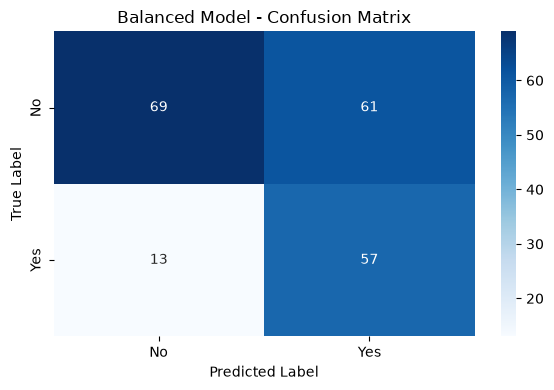

In [33]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    balanced_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Balanced Model - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

In [34]:
results = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Original_Prediction": y_pred,
    "Balanced_Prediction": balanced_pred
})

results.head(10)

,Actual_Churn,Original_Prediction,Balanced_Prediction
0,No,No,Yes
1,No,No,No
2,No,Yes,Yes
3,No,No,No
4,Yes,Yes,Yes
5,No,Yes,Yes
6,No,Yes,Yes
7,Yes,Yes,Yes
8,No,No,No
9,Yes,No,Yes


In [35]:
results.to_csv(
    "Day41_Customer_Churn_Predictions.csv",
    index=False
)

print("Prediction results saved successfully.")

Prediction results saved successfully.
